In [29]:
from rdkit import Chem
import pickle
import os
import json
import numpy as np
import xgboost

from shared.ml_helper import make_fingerprint # pyright: ignore[reportMissingImports]
from matplotlib import pyplot as plt
from cycler import cycler

from matplotlib.colors import ListedColormap
import numpy as np

# Example: define your own RGB color palette
# Replace these tuples with your desired RGB codes (values between 0 and 1)
custom_colors = [
    (169, 27, 46),  # blue-ish
    (0, 138, 173),  # red-ish
    (0, 48, 136),  # green-ish
    (138, 26, 155),  # yellow-ish
    (240, 137, 0)   # purple-ish
]

custom_c = [ tuple(c[i] / 256.0 for i in range(3)) for c in custom_colors ]

custom_cmap = ListedColormap(custom_c)
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}

In [30]:
# Data analysis



arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: '-H+ to bond',
    9: '-H+ to atom',
    10: 'elimination to bond'
}


training_dir = "training_sets/20260202"


# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []
contributors = {}
count_dirs = 0
count_arrows = 0

for subdir in subdirs:
    count_dirs += 1
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {pkl_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    contributor = data.get('contributor')
    if contributor in contributors or None in contributors:
        if contributor == '':
             contributors[None] += 1
        else:
            contributors[contributor] += 1
    else:
        if contributor == '':
             contributors[None] = 1
        else:
            contributors[contributor] = 1
    for id, info in choices.items():
        # bitvector for the mechanism
        if info['probable'] is None:
            continue
        try:
            sum_finger_print = make_fingerprint(sm, info['mechanism'])
        except:
             print(f"Error processing {training_dir}/{subdir} mechanism {info['mechanism']}")
        bitvectors.append(sum_finger_print)
        
        count_arrows += 1
        outcomes.append(info['probable'])
        # Track the origin of each bitvector
        with open("bitvector_origins.txt", "w") as origin_file:
            origin_file.write(f"{len(bitvectors)-1},{training_dir}/{subdir},{id}\n")


print(f"total directories: {count_dirs}, total arrows: {count_arrows}")
# with open(f'{training_dir}/bitvectors.csv', 'w', newline='') as csvfile:
#     writer = csv.writer(csvfile)
#     for bv, outcome in zip(bitvectors, outcomes):
#         writer.writerow(bv + [outcome])

[11:59:37] 

****
Range Error
idx
Violation occurred on line 198 in file /home/conda/feedstock_root/build_artifacts/rdkit-meta_1767159473677/work/Code/GraphMol/ROMol.cpp
Failed Expression: 11 < 11
----------
Stacktrace:
 0# Invar::Invariant::toString[abi:cxx11]() const in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/../../../libRDKitRDGeneral.so.1
 1# Invar::operator<<(std::ostream&, Invar::Invariant const&) in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/../../../libRDKitRDGeneral.so.1
 2# RDKit::ROMol::getAtomWithIdx(unsigned int) in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/Chem/../../../../libRDKitGraphMol.so.1
 3# 0x00007FF0491642E4 in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/Chem/rdchem.so
 4# boost::python::objects::function::call(_object*, _object*) const in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/../../../libboost_python313.so.1.86.0
 5# 0x00007FF08F1B17A9 in /home/rd611/.cond

Error processing training_sets/20260202/60 mechanism [4, 5, 11, None, None]
Error processing training_sets/20260202/60 mechanism [4, 6, 11, None, None]
Error processing training_sets/20260202/60 mechanism [9, 11, 7, 8, None]
Error processing training_sets/20260202/60 mechanism [0, 11, 8, None, None]
Error processing training_sets/20260202/60 mechanism [9, 11, 10, 8, None]
Error processing training_sets/20260202/60 mechanism [1, 5, 10, None, 11]
Error processing training_sets/20260202/60 mechanism [1, 6, 10, None, 11]
Error processing training_sets/20260202/60 mechanism [1, 11, 4, None, 5]
total directories: 403, total arrows: 9486


In [31]:
# Data analysis



import csv


arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: '-H+ to bond',
    9: '-H+ to atom',
    10: 'elimination to bond'
}


training_dir = "finetuning_combined"


# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
# subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors_finetuning = []
outcomes_finetuning = []

count_dirs_finetuning = 0
count_arrows_finetuning = 0

for subdir in subdirs:
    count_dirs_finetuning += 1
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {pkl_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    
    for id, info in choices.items():
        # bitvector for the mechanism
        if info['probable'] is None:
            continue
        try:
            sum_finger_print = make_fingerprint(sm, info['mechanism'])
        except Exception as e:
             print(f"Error processing {training_dir}/{subdir} mechanism {info['mechanism']}: {e}")
        bitvectors_finetuning.append(sum_finger_print)
        
        count_arrows_finetuning += 1
        outcomes_finetuning.append(info['probable'])
        # Track the origin of each bitvector
        with open("bitvector_origins.txt", "a") as origin_file:
            origin_file.write(f"{len(bitvectors_finetuning)-1},{training_dir}/{subdir},{id}\n")


print(f"total directories: {count_dirs_finetuning}, total arrows: {count_arrows_finetuning}")
with open(f'{training_dir}/bitvectors.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    for bv, outcome in zip(bitvectors_finetuning, outcomes_finetuning):
        writer.writerow(bv + [outcome])

total directories: 65, total arrows: 123


In [34]:
bitvectors_finetuning = []
set_bitvectors = set(tuple(bv) for bv in bitvectors + bitvectors_finetuning)
print(f"Total unique bitvectors: {len(set_bitvectors)}")
print(f"Total bitvectors: {len(bitvectors)}")
with open("unique_bitvectors.txt", "w") as ubv_file:
    for bv in set_bitvectors:
        ubv_file.write(','.join(map(str, bv)) + '\n')


Total unique bitvectors: 6323
Total bitvectors: 9486


In [33]:
type(bv[61])

int

In [ ]:
import json
import pickle
from pathlib import Path

from IPython.display import display
from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole

IPythonConsole.drawOptions.addAtomIndices = True

with open("bitvector_origins.txt", "r") as origin_file:
    bv_origins = origin_file.readlines()

for i, bv in enumerate(bitvectors):
    if bv[1] ==1 and bv[56]==1 and bv[52]==1 and bv[133]==1:
        print(bv)
        idx_str, folder_str, choice_id = [x.strip() for x in bv_origins[i].split(",")]
        folder = Path(folder_str)

        with open(folder / "data.json", "r") as f:
            data = json.load(f)
        with open(folder / "sm.pkl", "rb") as f:
            sm = pickle.load(f)

        choice = data["choices"][choice_id]

        print(f"bitvector index: {idx_str}")
        print(f"folder: {folder}")
        print(f"choice id: {choice_id}")
        print(f"mechanism: {choice['mechanism']}")
        print(f"probable: {choice['probable']}")

        display(sm)
        print("-" * 60)

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, recall_score, precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay, auc

In [36]:
from xgboost import XGBClassifier

In [37]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

ratio = len(outcomes)/sum(outcomes)
print(ratio)

# XGBoost Regression classifier
clf = XGBClassifier(scale_pos_weight = 7, eval_metric='logloss', max_depth=10)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
#joblib.dump(clf, 'models/v13/xg_model.pkl')
#clf.save_model('models/v81/xg_model.json')

6.596662030598053
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      2024
           1       0.78      0.87      0.82       348

    accuracy                           0.95      2372
   macro avg       0.88      0.92      0.90      2372
weighted avg       0.95      0.95      0.95      2372



In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import os
import pickle

pos_ft_weight = 30
neg_ft_weight = 200

base_samples = [(bv, outcome, False) for bv, outcome in zip(bitvectors, outcomes)]
base_samples += [(bv, outcome, True) for bv, outcome in zip(bitvectors_finetuning, outcomes_finetuning)]

group_ids = {}
groups = []
for bv, outcome, _ in base_samples:
    key = (tuple(bv), outcome)
    if key not in group_ids:
        group_ids[key] = len(group_ids)
    groups.append(group_ids[key])

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(base_samples, groups=groups))

X_train = [base_samples[i][0] for i in train_idx]
y_train = [base_samples[i][1] for i in train_idx]
X_test = [base_samples[i][0] for i in test_idx]
y_test = [base_samples[i][1] for i in test_idx]

sample_weight = []
for i in train_idx:
    bv, outcome, is_finetuning = base_samples[i]
    if is_finetuning:
        sample_weight.append(pos_ft_weight if outcome == 1 else neg_ft_weight)
    else:
        sample_weight.append(1.0)

clf = XGBClassifier(
    scale_pos_weight=6,
    eval_metric='aucpr',
    max_depth=8
)

clf.fit(X_train, y_train, sample_weight=sample_weight)
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
#joblib.dump(clf, 'models/v13/xg_model.pkl')
#clf.save_model('models/v105nf/xg_model.json')

# save model and the split information to avoid leakage during later evaluation
model_dir = "models/v109"
os.makedirs(model_dir, exist_ok=True)
clf.save_model(os.path.join(model_dir, "xg_model.json"))

split_meta = {
    "train_idx": train_idx.tolist(),
    "test_idx": test_idx.tolist(),
    "base_samples": base_samples,   # original combined samples (bitvector, outcome, is_finetuning)
    "groups": groups,
    "weighting": {"positive": pos_ft_weight, "negative": neg_ft_weight},
    "X_test": X_test,
    "y_test": y_test
}
with open(os.path.join(model_dir, "split_data.pkl"), "wb") as f:
    pickle.dump(split_meta, f)

print(f"Saved model and split metadata to {model_dir}")

              precision    recall  f1-score   support

           0       0.97      0.95      0.96      1666
           1       0.76      0.81      0.79       304

    accuracy                           0.93      1970
   macro avg       0.87      0.88      0.87      1970
weighted avg       0.93      0.93      0.93      1970

Saved model and split metadata to models/v108


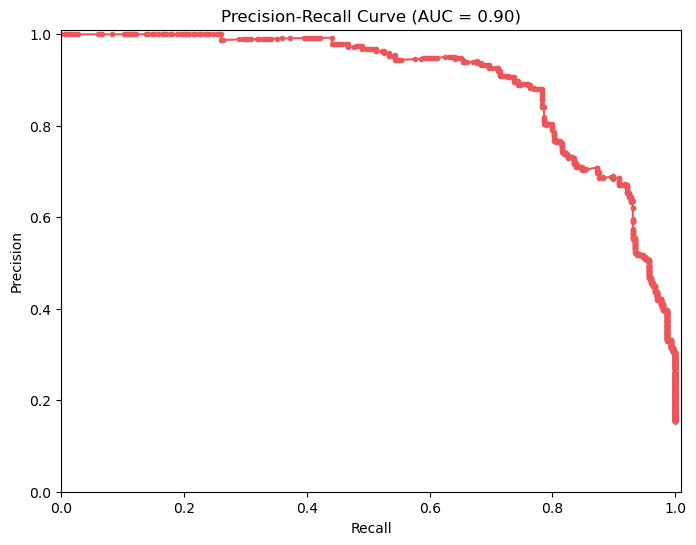

In [40]:
# Make predictions on the test set


clf = XGBClassifier()
clf.load_model("models/v108/xg_model.json")
y_pred = clf.predict_proba(X_test)[:, 1]
 
# Calculate precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_pred)
 
# Calculate the area under the PR curve
auc_score = auc(recall, precision)
 
# Plot the Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label='PR Curve', color='#ea565aff')
plt.xlim(0, 1.01)
plt.ylim(0, 1.01)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.show()
#plt.savefig('pr_curve_3.svg')
 

In [45]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

model = XGBClassifier(
    eval_metric="aucpr",
    random_state=42,
    scale_pos_weight =7
)

param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, 12]
}

cv = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="average_precision",   # or accuracy, neg_log_loss, etc.
    cv=5,
    n_jobs=-1,
    verbose=1
    
)

cv.fit(X_train, y_train)

print("Best max_depth:", cv.best_params_["max_depth"])
print("Best CV score:", cv.best_score_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits


Best max_depth: 8
Best CV score: 0.8586085154568514


In [ ]:
# Define a function to calculate evaluation metrics for a given threshold
def evaluate_threshold(y_true, y_pred_proba, threshold):
    y_pred = (y_pred_proba >= threshold).astype(int)
    precision, recall, _ = precision_recall_curve(y_true, y_pred)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
    balanced_accuracy = (recall[1] + recall[0]) / 2
    print("     precision    recall   f1-score ")
    print(f"0     {precision[0]:.4f}       {recall[0]:.4f}      {f1[0]:.4f}")
    print(f"1     {precision[1]:.4f}       {recall[1]:.4f}      {f1[1]:.4f}")
    print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
    return precision, recall, f1, balanced_accuracy


In [150]:
evaluate_threshold(y_test, y_pred_proba, 0.3)

     precision    recalll   f1-score 
0     0.1150       1.0000      0.2062
1     0.5720       0.8614      0.6875
Balanced Accuracy: 0.9307


(array([0.11495845, 0.572     , 1.        ]),
 array([1.        , 0.86144578, 0.        ]),
 array([0.20621116, 0.68749995, 0.        ]),
 np.float64(0.9307228915662651))

In [25]:
precisions =[]
precisions_sd = []
recalls = []
recalls_sd =[]
f1_scores = []
f1_scores_sd = []
from sklearn.metrics import f1_score
pos_weight = 15

iter = 10
for i in range(pos_weight):
    precision = []
    recall = []
    f1 = []
    for k in range(iter):
        X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)
        clf = XGBClassifier(scale_pos_weight = i+1, eval_metric='logloss')
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        # Get recall for positive class only (label=1)
        recall.append(recall_score(y_test, y_pred, pos_label=1))
        precision.append(precision_score(y_test, y_pred, pos_label=1))
        f1.append(f1_score(y_test, y_pred, pos_label=1))
    precisions.append(np.mean(np.array(precision)))
    precisions_sd.append(np.std(np.array(precision)))
    recalls.append(np.mean(np.array(recall)))
    recalls_sd.append(np.std(np.array(recall)))
    f1_scores.append(np.mean(np.array(f1)))
    f1_scores_sd.append(np.std(np.array(f1)))



In [23]:
print(f1_scores_sd)

[np.float64(0.048674321728475835), np.float64(0.02855178238536098), np.float64(0.02941580328073533), np.float64(0.03670433443735363), np.float64(0.03524226180508704), np.float64(0.03106724645176485), np.float64(0.0342592664362103), np.float64(0.02363628565787127), np.float64(0.03595755206197308), np.float64(0.04478477815356536), np.float64(0.03074396673467343), np.float64(0.024321682729249908), np.float64(0.03243233341493752), np.float64(0.03392116020836987), np.float64(0.05165047721339581)]


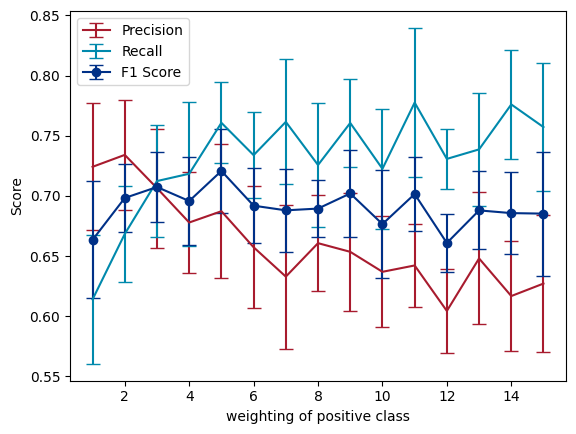

In [24]:
from matplotlib import pyplot as plt
from cycler import cycler
plt.errorbar(range(1, pos_weight+1), precisions, yerr=precisions_sd, label='Precision', capsize=5)
plt.errorbar(range(1, pos_weight+1), recalls, yerr =recalls_sd, label='Recall', capsize=5)
plt.errorbar(range(1, pos_weight+1), f1_scores, yerr=f1_scores_sd, label='F1 Score', fmt='-o', capsize=5)
plt.rc('axes', prop_cycle=cycler('color', custom_c))
plt.xlabel('weighting of positive class')
plt.ylabel('Score')
plt.legend()
#plt.show()
plt.savefig('pos_weighting.png', dpi=300)

In [15]:
np.sum(np.array(bitvectors), axis=0)

array([  20,  395,    0,  341,  318,  203,    6,   15,    0,    0,  134,
       1158,    6,  493,  585,  166,   54,   12,  835,  451,    0,   21,
        640,  124,  283,    6,    0,    0,    0,    0,    2,   96,   95,
         31,    0,  284,   66,   35,  754,  406,  308,  124,  139,    0,
         29, 1183,   86,  279,  648,  184,  187,   41,  816,  441,    0,
         19, 1083,   51,   54,    0,   37,   19,    0,    0,    1,   12,
         12,   10,    0,  344,   99,   67,  982,  294,  221,  412,   57,
          0,   36,  514,    0,    0,  214,  451,    4,    0,  314,  160,
         55,   26,    7])

In [82]:
np.array(bitvectors).shape

(1506, 91)

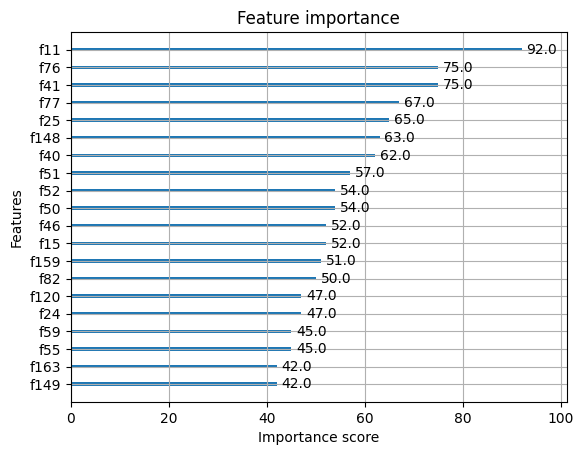

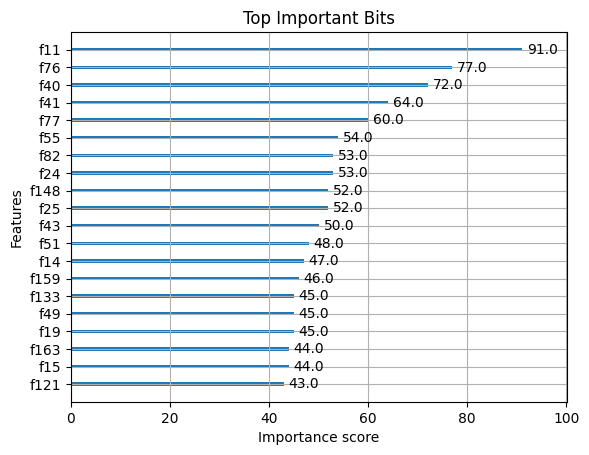

In [77]:
clf1 = XGBClassifier()
clf1.load_model('models/v14/xg_model.json')
clf2 = XGBClassifier()
clf2.load_model('models/v13/xg_model.json')
xgboost.plot_importance(clf1, max_num_features=20)
xgboost.plot_importance(clf2, max_num_features=20)
plt.title("Top Important Bits")
plt.show()

In [35]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)


clf = RandomForestClassifier(
    n_estimators=100,     # number of trees
    max_depth=None,       # let trees grow until pure
    class_weight='balanced',  # helpful for imbalanced classes
    random_state=42
)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9521531100478469
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.97      2381
           1       0.83      0.76      0.80       336

    accuracy                           0.95      2717
   macro avg       0.90      0.87      0.89      2717
weighted avg       0.95      0.95      0.95      2717



In [41]:
%run ml_tools/get_feature.py 10

Feature at index 10: Atom 1 - Charge Bit


In [95]:
clf = xgboost.XGBClassifier()
clf.load_model('models/v12/xg_model.json')
#clf = joblib.load('models/v12/xg_model.pkl')

In [ ]:
beckmann = Chem.MolFromSmiles('[OH2+]N=C1CCCCC1')
alkyl = Chem.MolFromSmiles('CC(C)(C)[CH2+]')
tert_brom = Chem.MolFromSmiles('CC1(Br)CCCCC1')
bv = Chem.MolFromSmiles('OOC1(O)CCCCC1')
bv_p = Chem.MolFromSmiles('[OH2+]OC1(O)CCCCC1')
r_aldol = Chem.MolFromSmiles('COC(C)([O-])C(C)(C)C(C)=O')
ohira_bestman = Chem.MolFromSmiles('CC(=[C])C1=CC=CC=C1')
diazo = Chem.MolFromSmiles('N#[N+]C1=CC=CC=C1')
brook = Chem.MolFromSmiles('CC(C[O-])[Si](C)(C)C')
benzoin = Chem.MolFromSmiles('N#CC([O-])(c1ccccc1)C(O)c1ccccc1')


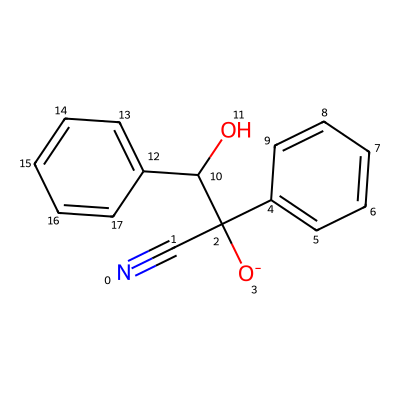

In [109]:
benzoin

In [110]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

In [120]:
clf = xgboost.XGBClassifier()
clf.load_model('models/v12/xg_model.json')
#clf = joblib.load('models/v12/xg_model.pkl')
mol = benzoin
arrow = [1, 3, 2, None, 1]
sum_finger_print = make_fingerprint(mol, arrow)

In [121]:
print(clf.predict(np.array([sum_finger_print]).reshape(1, -1)))

[1]


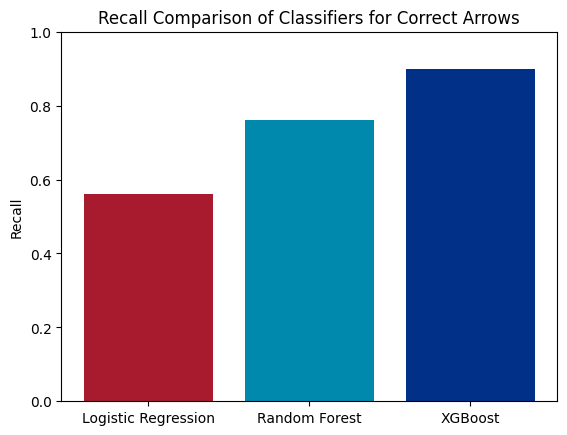

In [36]:
recalls = [0.56, 0.76, 0.90]
labels = ["Logistic Regression", "Random Forest", "XGBoost"]
plt.bar(labels, recalls, color=custom_c[:len(labels)])
plt.ylabel("Recall")
plt.title("Recall Comparison of Classifiers for Correct Arrows")
plt.ylim(0, 1)
plt.show()